# COMP9417 Project: starter notebook

This notebook loads the dataset, shows how day D and day D+1 are defined, builds a day-ahead
table for both targets, and computes the two required baselines by year. It ends with a very
simple model trained on 2010-2013 so you can see the evaluation protocol in action.

Run it from the kit's root folder, with the libraries in `requirements.txt` installed.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "harness")
import dayahead as da          # the same helpers the marking runner uses

df = da.load_dataset("data/nem_weather_halfhourly_2010_2026.csv")
print(df.shape, df.index.min(), "to", df.index.max())
df.head()

(295104, 18) 2010-01-01 00:30:00 to 2026-11-01 00:00:00


,nsw_demand,nsw_price,qld_demand,qld_price,vic_demand,vic_price,syd_temp,syd_rh,syd_cloud,syd_solar,mel_temp,mel_rh,mel_cloud,mel_solar,bne_temp,bne_rh,bne_cloud,bne_solar
timestamp,,,,,,,,,,,,,,,,,,
2010-01-01 00:30:00,7809.31,21.50,5422.25,20.67,5111.02,20.11,21.20,95.5,72.5,0.0,27.15,54.0,52.0,0.0,22.50,82.5,97.5,0.0
2010-01-01 01:00:00,7483.69,20.98,5315.98,20.15,4960.03,19.40,21.10,96.0,87.0,0.0,26.80,56.0,21.0,0.0,22.30,83.0,95.0,0.0
2010-01-01 01:30:00,7117.23,20.06,5186.70,18.95,5283.40,19.63,21.05,96.0,87.0,0.0,26.35,59.0,11.0,0.0,22.25,83.0,95.0,0.0
2010-01-01 02:00:00,6812.03,17.93,5050.83,16.88,5046.15,17.05,21.00,96.0,87.0,0.0,25.90,62.0,1.0,0.0,22.20,83.0,95.0,0.0
2010-01-01 02:30:00,6544.33,17.43,4924.74,16.28,4796.18,15.84,21.00,96.5,84.5,0.0,25.50,64.5,4.5,0.0,22.20,83.0,96.0,0.0


## Timestamps and days

Each timestamp marks the **end** of a half-hour interval, in market time (AEST, UTC+10, no
daylight saving). Day D is made of the 48 intervals stamped D 00:30, D 01:00, ..., D 23:30 and
D+1 00:00. `da.market_day` maps each timestamp to its day.

In [2]:
df["day"] = da.market_day(df.index)
df["period"] = ((df.index - pd.Timedelta("30min")).hour * 2
                + (df.index - pd.Timedelta("30min")).minute // 30)   # 0..47
df[["day", "period", "nsw_demand", "nsw_price"]].iloc[44:52]

,day,period,nsw_demand,nsw_price
timestamp,,,,
2010-01-01 22:30:00,2010-01-01,44,8210.54,21.70
2010-01-01 23:00:00,2010-01-01,45,8041.77,22.27
2010-01-01 23:30:00,2010-01-01,46,7782.68,21.50
2010-01-02 00:00:00,2010-01-01,47,7574.85,21.00
2010-01-02 00:30:00,2010-01-02,0,7343.30,20.67
2010-01-02 01:00:00,2010-01-02,1,7099.73,19.27
2010-01-02 01:30:00,2010-01-02,2,6779.80,17.92
2010-01-02 02:00:00,2010-01-02,3,6497.47,15.63


## A first look at drift

Midday demand has fallen as rooftop solar has grown, while the evening peak has not.
Negative prices were almost unknown before 2020.

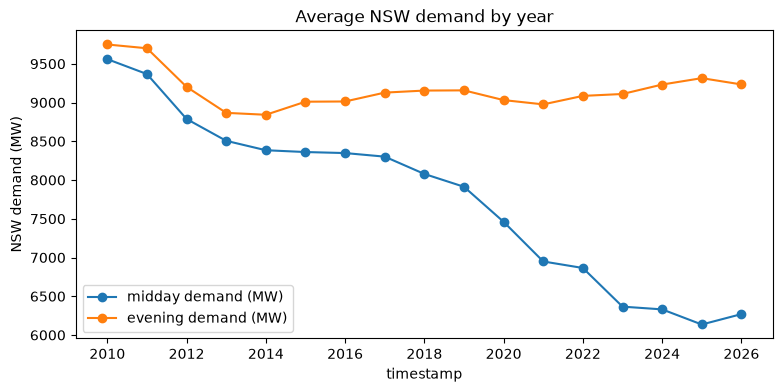

,midday demand (MW),evening demand (MW),negative-price share (%)
timestamp,,,
2010,9559.5,9748.6,0.0
2011,9367.2,9700.0,0.0
2012,8787.5,9201.8,0.0
2013,8505.7,8866.7,0.0
2014,8384.3,8841.9,0.0
2015,8361.0,9010.5,0.0
2016,8347.8,9013.4,0.0
2017,8301.6,9127.8,0.0
2018,8078.2,9154.2,0.0


In [3]:
year = df.index.year
noon = df["period"].isin([23, 24, 25, 26])      # 11:30-13:30
evening = df["period"].isin([37, 38, 39])       # 18:30-20:00
summary = pd.DataFrame({
    "midday demand (MW)": df.loc[noon, "nsw_demand"].groupby(year[noon]).mean(),
    "evening demand (MW)": df.loc[evening, "nsw_demand"].groupby(year[evening]).mean(),
    "negative-price share (%)": (df["nsw_price"] < 0).groupby(year).mean() * 100,
}).round(1)
ax = summary[["midday demand (MW)", "evening demand (MW)"]].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("NSW demand (MW)"); ax.set_title("Average NSW demand by year")
plt.show()
summary

## The day-ahead table

One row per half-hour of day D+1. Targets: demand (MW), and whether the price is above
the mean price of day D. Inputs here are only examples: values from day D and day D-6
(same half-hour yesterday and last week) and the weather for D+1. Designing better inputs is
part of your work. Everything is shifted by whole days, so no information from D+1's market
values leaks into the inputs.

In [4]:
daily_price_mean = df.groupby("day")["nsw_price"].transform("mean")
t = pd.DataFrame(index=df.index)
t["day"], t["period"] = df["day"], df["period"]
t["y_demand"] = df["nsw_demand"]
t["y_up"] = (df["nsw_price"] > daily_price_mean.shift(48)).astype(int)
t["demand_lag1"] = df["nsw_demand"].shift(48)         # same half-hour yesterday
t["demand_lag7"] = df["nsw_demand"].shift(48 * 7)     # same half-hour last week
t["up_lag1"] = (df["nsw_price"].shift(48) > daily_price_mean.shift(48)).astype(int)
t["up_lag7"] = (df["nsw_price"].shift(48 * 7) > daily_price_mean.shift(48)).astype(int)  # vs day D mean
for c in da.WEATHER_COLS:
    t[c] = df[c]                                      # weather of D+1 itself (allowed)
t = t.iloc[48 * 7:].dropna()
t["year"] = t["day"].dt.year
t.head()

,day,period,y_demand,y_up,demand_lag1,demand_lag7,up_lag1,up_lag7,syd_temp,syd_rh,...,syd_solar,mel_temp,mel_rh,mel_cloud,mel_solar,bne_temp,bne_rh,bne_cloud,bne_solar,year
timestamp,,,,,,,,,,,,,,,,,,,,,
2010-01-08 00:30:00,2010-01-08,0,7498.35,0,7433.46,7809.31,0,0,20.95,74.5,...,0.0,15.20,87.0,0.0,0.0,22.90,88.0,98.5,0.0,2010
2010-01-08 01:00:00,2010-01-08,1,7242.52,0,7216.30,7483.69,0,0,20.90,75.0,...,0.0,14.70,89.0,0.0,0.0,22.70,88.0,99.0,0.0,2010
2010-01-08 01:30:00,2010-01-08,2,6972.24,0,6940.48,7117.23,0,0,20.85,75.5,...,0.0,14.00,91.5,0.0,0.0,22.35,89.5,99.0,0.0,2010
2010-01-08 02:00:00,2010-01-08,3,6706.22,0,6692.82,6812.03,0,0,20.80,76.0,...,0.0,13.30,94.0,0.0,0.0,22.00,91.0,99.0,0.0,2010
2010-01-08 02:30:00,2010-01-08,4,6525.71,0,6477.56,6544.33,0,0,20.80,76.5,...,0.0,13.25,94.0,0.0,0.0,21.95,92.0,99.5,0.0,2010


## Baselines by year

Both baselines must be reported in your project. They are hard to beat.

In [5]:
def yearly(t, pred_demand, pred_up):
    g = t.assign(pd_=pred_demand, pu_=pred_up).groupby("year")
    return pd.DataFrame({
        "MAPE (%)": g.apply(lambda x: da.mape(x.y_demand, x.pd_)),
        "balanced acc. (%)": g.apply(lambda x: da.balanced_accuracy(x.y_up, x.pu_)),
    }).round(2)

base1 = yearly(t, t.demand_lag1, t.up_lag1)
base7 = yearly(t, t.demand_lag7, t.up_lag7)
pd.concat({"same half-hour yesterday": base1, "same half-hour last week": base7}, axis=1)

same half-hour yesterday                   same half-hour last week  \
                     MAPE (%) balanced acc. (%)                 MAPE (%)   
year                                                                       
2010                     4.92             78.60                     4.91   
2011                     4.76             76.17                     5.22   
2012                     5.04             73.31                     4.81   
2013                     5.29             74.63                     5.52   
2014                     4.93             73.99                     4.93   
2015                     5.35             74.72                     5.76   
2016                     5.46             69.83                     5.84   
2017                     5.95             68.71                     6.23   
2018                     5.20             72.26                     6.34   
2019                     5.75             71.53                     6.53   
2020                     5.89             72.26                     7.15   
2021                     5.73             72.85                     7.17   
2022                     5.89             70.82                     7.28   
2023                     6.46             76.00                     7.90   
2024                     7.30             76.39                     9.29   
2025                     8.07             79.42                    10.55   
2026                     6.89             73.87                     9.35   

                        
     balanced acc. (%)  
year                    
2010             74.44  
2011             74.18  
2012             69.98  
2013             72.44  
2014             74.28  
2015             72.06  
2016             67.56  
2017             68.30  
2018             69.10  
2019             69.10  
2020             69.94  
2021             69.26  
2022             67.41  
2023             73.31  
2024             72.48  
2025             75.40  
2026             70.20

## The protocol with a very simple model

Train on 2010-2013, validate on 2014, then freeze the model and evaluate every later year.
This ridge regression is only an illustration; the project asks for at least two algorithms per
task, from different families, with justified features.

Validation (2014) MAPE: 4.08%


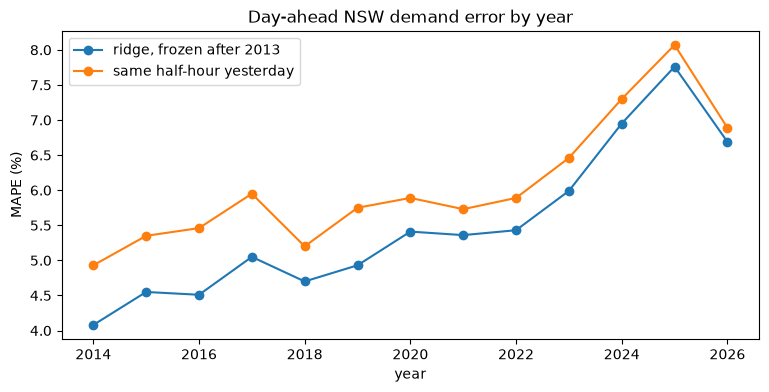

In [6]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feats = ["demand_lag1", "demand_lag7", "syd_temp", "syd_solar", "period"]
X = t[feats].assign(sin_p=np.sin(2 * np.pi * t.period / 48), cos_p=np.cos(2 * np.pi * t.period / 48))
train, valid = t.year <= 2013, t.year == 2014
model = make_pipeline(StandardScaler(), Ridge()).fit(X[train], t.y_demand[train])
print(f"Validation (2014) MAPE: {da.mape(t.y_demand[valid], model.predict(X[valid])):.2f}%")

frozen = yearly(t, model.predict(X), t.up_lag1)["MAPE (%)"]
ax = pd.DataFrame({"ridge, frozen after 2013": frozen, "same half-hour yesterday": base1["MAPE (%)"]}
                  ).loc[2014:].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("MAPE (%)"); ax.set_title("Day-ahead NSW demand error by year")
plt.show()

## Next steps

* `example_package/` shows a complete model package (`model.py`, `train.py`, `artifacts/`).
* `template/model.py` is a blank Forecaster to start from.
* `python check_submission.py your_package` runs your package exactly as in marking.

In [7]:
import sys, json, numpy, pandas, sklearn
print('PROBE ' + json.dumps({'executable': sys.executable, 'python': sys.version.split()[0], 'numpy': numpy.__version__, 'pandas': pandas.__version__, 'sklearn': sklearn.__version__}))

PROBE {"executable": "/Users/tristanliu/Documents/MyProject/9417/.venv/bin/python", "python": "3.11.8", "numpy": "2.4.6", "pandas": "3.1.0", "sklearn": "1.9.1"}
